# Metabolite Hit Validation (external cohorts)
Here I will read in metacardis data with available antibiotic use information and see how my findings compare. 

Sarah has also performed this analysis for the SOL cohort. She's send me her findings, and I will combine all data here for plotting in R.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from regression_functions import *

# Metacardis

## Load the excel sheets into pandas DFs and save as .csv

In [2]:
'''These data come from Fromentin 2022'''
##############################################
# microbes = pd.read_excel("41591_2022_1688_MOESM3_ESM.xlsx", sheet_name=10, header=1)
# metabolites = pd.read_excel("41591_2022_1688_MOESM3_ESM.xlsx", sheet_name=12, header=1)
# clients = pd.read_excel("41591_2022_1688_MOESM3_ESM.xlsx", sheet_name=9, header=1)
#other_drugs = pd.read_excel("metacardis_data/41591_2022_1688_MOESM3_ESM.xlsx", sheet_name=14, header=1)

'These data come from Fromentin 2022'

In [3]:
# microbes.to_csv("metacardis_microbes.csv", index=False)
# metabolites.to_csv("metacardis_metabolites.csv", index=False)
# clients.to_csv("metacardis_client_metadata.csv", index=False)
#other_drugs.to_csv("metacardis_data/metacardis_other_drugs.csv", index=False)

In [4]:
'''These data come from Forslund 2021'''
##############################################
# abx_count = pd.read_excel("metacardis_data/Table1-4_Metadata.xlsx", sheet_name=6, header=0)
# group_char = pd.read_excel("metacardis_data/Table1-4_Metadata.xlsx", sheet_name=1, header=0)
# individ_metadata = pd.read_excel("metacardis_data/Table1-4_Metadata.xlsx", sheet_name=2, header=0)
# anti_diab = pd.read_excel("metacardis_data/Table1-4_Metadata.xlsx", sheet_name=4, header=0)

'These data come from Forslund 2021'

In [5]:
# abx_count.to_csv("metacardis_data/metacardis_abx_count.csv", index=False)
# group_char.to_csv("metacardis_data/metacardis_group_characteristics.csv", index=False)
# individ_metadata.to_csv("metacardis_data/metacardis_2021_client_metadata.csv", index=False)
# anti_diab.to_csv("metacardis_data/metacardis_other_med_use.csv", index=False)

In [6]:
# Have not implemented this yet
# individ_metadata_small = [['ID', 'PatientGroup', 'BMI', 'AGE', 'CENTER', 'pa_work_2cl', 'aHEI', 'Gender']]

## Check/Clean the DFs

In [7]:
clients_fromentin2022 = pd.read_csv("metacardis_data/metacardis_client_metadata.csv")
microbes = pd.read_csv("metacardis_data/metacardis_microbes.csv")
metabolites = pd.read_csv("metacardis_data/metacardis_metabolites.csv")
statin_info = pd.read_csv("metacardis_data/metacardis_other_drugs.csv")

In [8]:
clients_forslund2021 = pd.read_csv("metacardis_data/metacardis_2021_client_metadata.csv")
abx_count = pd.read_csv("metacardis_data/metacardis_abx_count.csv")
group_char = pd.read_csv("metacardis_data/metacardis_group_characteristics.csv")
anti_diab = pd.read_csv("metacardis_data/metacardis_other_med_use.csv")

In [9]:
clients_fromentin2022

,ID,Status,Read count,High quality read count,High quality clean read count,Homo sapiens GRCh37.p10 may2014 excluded read count,Bos Taurus 4.6.1 may2014 excluded read count,A thaliana may2014 excluded read count,Mapped read count,Percentage of mapped read count,...,Fasting plasma CRP (mg/L),HbA1c (%),Systolic blood pressure (mmHg),Diastolic blood pressure (mmHg),Left ventricular ejection fraction (%),Fasting plasma pro-ANP (pmol/L),Physical activity (h/week),Gender,Nationality,Diabetic status
0,x14MCx2088,HC275,22701641.0,21272456.0,21266684.0,5766.0,12.0,11.0,14838284.0,69.772438,...,0.475,5.2,134.0,75.5,58.0,261.0,9.781250,Female,France,No
1,x14MCx1929,HC275,21528200.0,20349954.0,20276835.0,73070.0,97.0,48.0,14240737.0,70.231557,...,1.080,5.5,119.5,69.5,72.0,669.0,6.510417,Male,France,No
2,x14MCx1616,HC275,23237795.0,21475583.0,21115176.0,360311.0,497.0,64.0,15255665.0,72.249765,...,0.100,5.3,124.5,72.0,55.0,212.0,8.583333,Female,France,No
3,x14MCx1706,HC275,22579768.0,21236137.0,21224377.0,11734.0,11.0,26.0,15928331.0,75.047343,...,1.340,5.4,118.0,74.0,79.0,411.0,NaN,Female,France,No
4,x14MCx2468,HC275,23075585.0,21265012.0,21243405.0,21537.0,43.0,69.0,15780949.0,74.286344,...,4.770,5.3,158.0,91.5,61.0,479.0,10.066667,Male,France,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1877,x30MCx2578,UMCC222,23054682.0,21791122.0,21785130.0,5963.0,25.0,41.0,16978830.0,77.937703,...,5.000,6.1,136.5,80.5,NaN,57.0,1.885417,Female,Danemark,Yes
1878,x30MCx3124,UMCC222,22968714.0,21733758.0,21707566.0,25871.0,92.0,284.0,15025652.0,69.218502,...,5.020,5.2,125.0,80.5,NaN,282.0,1.770833,Female,Danemark,No
1879,x30MCx1693,UMCC222,33842613.0,31890056.0,31816610.0,73426.0,117.0,16.0,24473641.0,76.920957,...,5.250,8.9,153.5,76.0,NaN,360.0,2.375000,Female,Danemark,Yes
1880,x30MCx1516,UMCC222,34005001.0,32577197.0,32402371.0,174591.0,570.0,173.0,25119557.0,77.523824,...,7.400,5.6,124.0,76.5,NaN,199.0,NaN,Female,Danemark,No


In [10]:
clients_fromentin2022['Status'] = clients_fromentin2022['Status'].str.replace(r'\d+', '', regex=True)

In [11]:
clients_fromentin2022.Status.value_counts()

Status
MMC     641
IHD     372
HC      275
UMCC    222
CIHD    158
ACS     112
HF      102
Name: count, dtype: int64

In [12]:
clients_fromentin2022 = clients_fromentin2022.rename(columns={
    'SampleID':'ID',
    'Read count': 'read_count', 
    'High quality clean read count': 'hq_clean_read_count',
    'Percentage of mapped read count': 'pct_mapped',
    'Percentage of unique mapped read count': 'pct_mapped_unique',
    'Age (years)': 'age',
    'BMI (kg/m²)': 'bmi',
    'Waist circumference (cm)': 'waist_circ',
    'Fasting plasma triglycerides (mmol/L)': 'triglycerides',
    'Fasting plasma adiponectin (mg/L)': 'adiponectin',
    'Fasting plasma CRP (mg/L)': 'crp',
    'HbA1c (%)': 'hba1c',
    'Systolic blood pressure (mmHg)': 'systolic_bp',
    'Diastolic blood pressure (mmHg)': 'diastolic_bp',
    'Left ventricular ejection fraction (%)': 'lvef',
    'Fasting plasma pro-ANP (pmol/L)': 'pro_ANP',
    'Physical activity (h/week)': 'activity_hr_week',
    'Gender': 'gender', 
    'Nationality': 'center',
    'Diabetic status': 'diabetic_status'
})

clients_fromentin2022.loc[clients_fromentin2022.center == 'Danemark', 'center'] = 'Denmark'

In [13]:
clients_fromentin_clean = clients_fromentin2022[[
    'ID', 'Status', 'read_count', 'hq_clean_read_count',
    'pct_mapped', 'Unique mapped read count', 'pct_mapped_unique',
    'age', 'bmi', 'gender', 'center', 'diabetic_status',
    'waist_circ', 'triglycerides', 'adiponectin', 'crp', 'hba1c',
    'systolic_bp', 'diastolic_bp', 'lvef', 'pro_ANP', 'activity_hr_week'
]].copy().drop_duplicates()

<Axes: xlabel='Status', ylabel='hba1c'>

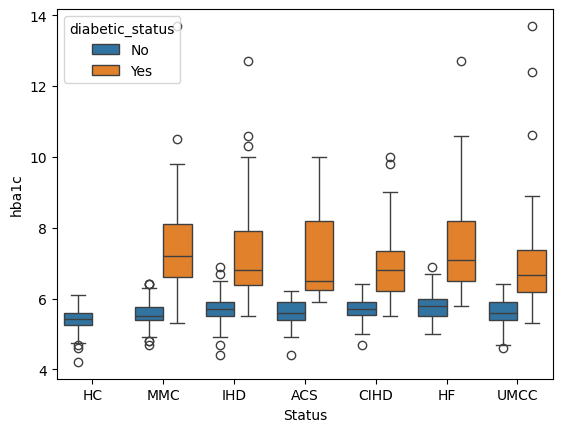

In [14]:
sns.boxplot(data=clients_fromentin_clean, x='Status', y='hba1c', hue='diabetic_status')

<Axes: xlabel='Status', ylabel='activity_hr_week'>

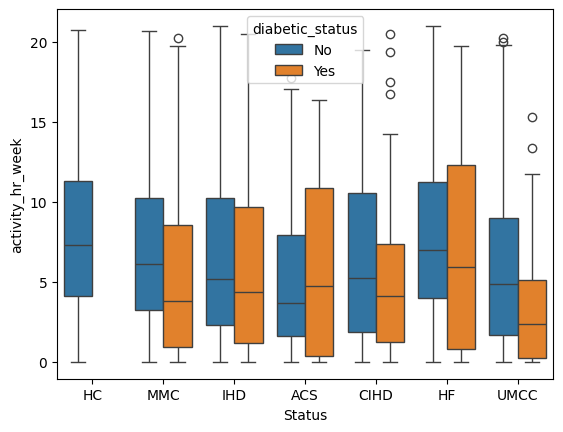

In [15]:
sns.boxplot(data=clients_fromentin_clean, x='Status', y='activity_hr_week', hue='diabetic_status')

In [16]:
clients_fromentin_clean.ID.nunique()

1087

In [17]:
# clients_fromentin_clean

In [18]:
dup_fromentin = clients_fromentin_clean[clients_fromentin_clean.ID.duplicated()]['ID'].tolist()
dup_fromentin_df = clients_fromentin_clean[clients_fromentin_clean['ID'].isin(dup_fromentin)].sort_values(by='ID')
dup_fromentin_df

,ID,Status,read_count,hq_clean_read_count,pct_mapped,Unique mapped read count,pct_mapped_unique,age,bmi,gender,...,waist_circ,triglycerides,adiponectin,crp,hba1c,systolic_bp,diastolic_bp,lvef,pro_ANP,activity_hr_week
925,x10MCx1144,IHD,22759924.0,21513605.0,79.963154,15533394.0,72.202655,66,25.04861,Male,...,93.0,0.9804,1.46,4.260,7.6,152.0,74.0,70.0,362.0,NaN
1407,x10MCx1144,CIHD,22759924.0,21513605.0,79.963154,15533394.0,72.202655,66,25.04861,Male,...,93.0,0.9804,1.46,4.260,7.6,152.0,74.0,70.0,362.0,NaN
1487,x10MCx1229,CIHD,23120257.0,22157040.0,80.959988,16101183.0,72.668475,65,26.73260,Male,...,93.5,1.0146,3.09,2.320,5.9,134.5,82.5,51.0,781.0,3.750000
1113,x10MCx1229,IHD,23120257.0,22157040.0,80.959988,16101183.0,72.668475,65,26.73260,Male,...,93.5,1.0146,3.09,2.320,5.9,134.5,82.5,51.0,781.0,3.750000
1195,x10MCx1333,IHD,21633230.0,19963109.0,78.165004,13507808.0,67.663849,63,49.99951,Male,...,132.4,1.1970,2.77,7.550,6.0,134.5,66.5,NaN,448.0,3.875000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1033,x30MCx3382,IHD,22312115.0,20989902.0,74.394049,13708889.0,65.311829,58,26.19533,Male,...,85.3,0.8700,6.90,0.100,5.5,123.5,69.5,60.0,405.0,13.645833
1584,x30MCx3388,HF,NaN,NaN,NaN,NaN,NaN,72,32.46377,Male,...,114.7,1.1600,3.17,2.150,7.1,125.0,54.0,42.0,NaN,0.000000
1039,x30MCx3388,IHD,NaN,NaN,NaN,NaN,NaN,72,32.46377,Male,...,114.7,1.1600,3.17,2.150,7.1,125.0,54.0,42.0,NaN,0.000000
1390,x30MCx3415,ACS,NaN,NaN,NaN,NaN,NaN,51,27.62346,Male,...,94.8,1.0000,7.06,0.832,6.0,133.0,91.5,60.0,NaN,NaN


In [19]:
dup_fromentin_df.Status.value_counts() 

Status
IHD     372
CIHD    158
MMC     154
ACS     112
HC      103
HF      102
UMCC     51
Name: count, dtype: int64

In [20]:
### Move onto Forslund

In [21]:
clients_forslund2021.set_index('SampleID', inplace=True)

In [22]:
clients_forslund2021.columns = clients_forslund2021.columns.str.lower()

In [23]:
clients_forslund2021.reset_index(inplace=True)

## Merge client metadata from both studies

In [24]:
# Subset col of interest from Fromentin 2022
# clients_fromentin_clean = (clients_fromentin2022
#                            [['ID','Status','Age (years)', 'BMI (kg/m²)',
#                              'Gender', 'Nationality']].copy())

# IHD372 and MMC372 both have subcategories
# IHD has CIHD, ACS, and HF
# MMC has a 372 cohort and a 269 cohort
# Only keep the larger categories to prevent duplicates
# status = ['HC275', 'MMC372', 'UMCC222', 'IHD372']

# clients_fromentin_clean.rename(columns={'BMI (kg/m²)': 'BMI'}, inplace=True)
# clients_fromentin_clean.rename(columns={'Age (years)': 'AGE'}, inplace=True)
# clients_fromentin_clean.rename(columns={'Nationality': 'CENTER'}, inplace=True)

# Change spelling of Danemark to Denmark to match other df
# clients_fromentin2022.Nationality.value_counts()

# clients_fromentin_clean = clients_fromentin_clean[clients_fromentin_clean['Status'].isin(status)]
clients_fromentin_clean.head() 

,ID,Status,read_count,hq_clean_read_count,pct_mapped,Unique mapped read count,pct_mapped_unique,age,bmi,gender,...,waist_circ,triglycerides,adiponectin,crp,hba1c,systolic_bp,diastolic_bp,lvef,pro_ANP,activity_hr_week
0,x14MCx2088,HC,22701641.0,21266684.0,69.772438,13393155.0,62.977167,56,21.22839,Female,...,71.0,0.4674,13.03,0.475,5.2,134.0,75.5,58.0,261.0,9.781250
1,x14MCx1929,HC,21528200.0,20276835.0,70.231557,12865029.0,63.446928,66,23.89748,Male,...,81.5,0.7866,8.48,1.080,5.5,119.5,69.5,72.0,669.0,6.510417
2,x14MCx1616,HC,23237795.0,21115176.0,72.249765,13554237.0,64.191921,63,19.55902,Female,...,69.7,0.8094,10.08,0.100,5.3,124.5,72.0,55.0,212.0,8.583333
3,x14MCx1706,HC,22579768.0,21224377.0,75.047343,14159012.0,66.711084,52,23.59283,Female,...,77.7,0.6612,8.55,1.340,5.4,118.0,74.0,79.0,411.0,NaN
4,x14MCx2468,HC,23075585.0,21243405.0,74.286344,13936699.0,65.604827,62,23.91582,Male,...,85.5,1.0260,5.14,4.770,5.3,158.0,91.5,61.0,479.0,10.066667


In [25]:
# This cell determines how many IDs are shared between the two studies
clients_forslund2021.rename(columns={'SampleID': 'ID'}, inplace=True)
test = clients_forslund2021[['ID','gender']].merge(clients_fromentin_clean[['ID', 'gender']], on=['ID'], how='inner').drop_duplicates()
test
# Also one can see here that 1.0 maps to male and 0.0 maps to female

,ID,gender_x,gender_y
0,x10MCx1135,1.0,Male
1,x10MCx1140,0.0,Female
2,x10MCx1144,1.0,Male
4,x10MCx1146,0.0,Female
5,x10MCx1150,0.0,Female
...,...,...,...
1583,x30MCx3382,NaN,Male
1585,x30MCx3384,NaN,Male
1586,x30MCx3388,NaN,Male
1588,x30MCx3414,NaN,Male


Clean up data so that values from the two papers match (like gender)

In [26]:
# Change gender encoding in Forslund 2021 paper metadata 
clients_forslund2021['gender_text'] = clients_forslund2021['gender'].apply(
    lambda x: 'Male' if x == 1 else 
    'Female' if x == 0
    else x)
clients_forslund2021.drop(columns='gender',inplace=True)
clients_forslund2021.rename(columns={'gender_text': 'gender'}, inplace=True)

# Outer merge to keep all folks
# Not merging on multiple columns bc they are filled to varying extents
all_clients = (clients_forslund2021.merge(
    clients_fromentin_clean, 
    how='outer', 
    on=['ID'], 
    suffixes=('_df1', '_df2')).drop_duplicates())

# Combine complementary columns
# Overrides NaNs for col that have data
shared_col = ['center', 'age', 'bmi', 'gender']

for col in shared_col: 
    all_clients[col] = all_clients[f'{col}_df1'].combine_first(all_clients[f'{col}_df2'])

# Drop the temp col
(all_clients.drop(columns=
                  [col + '_df1' for col in shared_col] + 
                  [col + '_df2' for col in shared_col], 
                  inplace=True))

all_clients.sort_values(by='ID')

,ID,patientgroup,smoke,pa_work_2cl,ahei,dash,dds,Status,read_count,hq_clean_read_count,...,hba1c,systolic_bp,diastolic_bp,lvef,pro_ANP,activity_hr_week,center,age,bmi,gender
0,x10MCx1114,3,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,France,59.0,38.154392,Female
1,x10MCx1132,3,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,France,73.0,44.634475,Female
2,x10MCx1133,3,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,France,73.0,NaN,Male
3,x10MCx1134,2a,0.0,1.0,18.144745,36.041306,12.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,France,42.0,44.365888,Female
4,x10MCx1135,3,0.0,1.0,NaN,NaN,NaN,MMC,22485512.0,21368919.0,...,9.2,154.5,68.5,71.0,386.0,0.0,France,57.0,27.719670,Male
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2716,x30MCx3414,8,NaN,NaN,NaN,NaN,NaN,HC,25741864.0,24459479.0,...,5.8,114.0,58.5,NaN,530.0,18.0,Denmark,43.0,25.022160,Male
2717,x30MCx3415,4,NaN,NaN,NaN,NaN,NaN,IHD,NaN,NaN,...,6.0,133.0,91.5,60.0,NaN,NaN,Denmark,51.0,27.623460,Male
2718,x30MCx3415,4,NaN,NaN,NaN,NaN,NaN,ACS,NaN,NaN,...,6.0,133.0,91.5,60.0,NaN,NaN,Denmark,51.0,27.623460,Male
2719,x30MCx3422,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Denmark,NaN,NaN,NaN


In [27]:
all_clients.ID.nunique()

2195

In [28]:
dup_post_merge = all_clients[all_clients.ID.duplicated()]['ID'].tolist()
len(dup_post_merge) # 154
dup_clients_df = all_clients[all_clients['ID'].isin(dup_post_merge)].sort_values(by='ID')

In [29]:
dup_clients_df.Status.value_counts()

Status
IHD     372
CIHD    158
MMC     154
ACS     112
HC      103
HF      102
UMCC     51
Name: count, dtype: int64

In [30]:
drop_ambiguous = all_clients[~all_clients['ID'].isin(dup_post_merge)]

In [31]:
drop_ambiguous

,ID,patientgroup,smoke,pa_work_2cl,ahei,dash,dds,Status,read_count,hq_clean_read_count,...,hba1c,systolic_bp,diastolic_bp,lvef,pro_ANP,activity_hr_week,center,age,bmi,gender
0,x10MCx1114,3,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,France,59.0,38.154392,Female
1,x10MCx1132,3,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,France,73.0,44.634475,Female
2,x10MCx1133,3,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,France,73.0,NaN,Male
3,x10MCx1134,2a,0.0,1.0,18.144745,36.041306,12.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,France,42.0,44.365888,Female
4,x10MCx1135,3,0.0,1.0,NaN,NaN,NaN,MMC,22485512.0,21368919.0,...,9.2,154.5,68.5,71.0,386.0,0.00,France,57.0,27.719670,Male
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2712,x30MCx3384,1,NaN,NaN,NaN,NaN,NaN,MMC,23104576.0,21966691.0,...,5.4,116.0,64.0,NaN,741.0,11.75,Denmark,70.0,29.547330,Male
2715,x30MCx3412,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Denmark,NaN,NaN,NaN
2716,x30MCx3414,8,NaN,NaN,NaN,NaN,NaN,HC,25741864.0,24459479.0,...,5.8,114.0,58.5,NaN,530.0,18.00,Denmark,43.0,25.022160,Male
2719,x30MCx3422,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Denmark,NaN,NaN,NaN


## Merge with antibiotic use data

In [34]:
# Merge client/covariates with abx use data
abx_count.rename(columns={'SampleID': 'ID'}, inplace=True)

clients_abxuse = (abx_count.merge(
    drop_ambiguous, 
    how='right', 
    on=['ID']).dropna(
    subset='ANTIBIOTICS_TOTAL'))

clients_abxuse

,ID,PatientGroup,ANTIBIOTICS_TOTAL,BETA_LACTAM,BISMUTH,FLUOROQUINOLONE,FOSFOMYCIN,FUSIDIC_ACID,GLYCOPEPTIDE,IMIDAZOLE,...,hba1c,systolic_bp,diastolic_bp,lvef,pro_ANP,activity_hr_week,center,age,bmi,gender
2,x10MCx1133,3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,France,73.0,NaN,Male
3,x10MCx1134,2a,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,France,42.0,44.365888,Female
4,x10MCx1135,3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,9.2,154.5,68.5,71.0,386.0,0.00,France,57.0,27.719670,Male
5,x10MCx1138,3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,France,42.0,38.221055,Male
7,x10MCx1143,3,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,France,71.0,39.817729,Female
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1664,x30MCx3384,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,5.4,116.0,64.0,NaN,741.0,11.75,Denmark,70.0,29.547330,Male
1665,x30MCx3412,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,Denmark,NaN,NaN,NaN
1666,x30MCx3414,8,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,5.8,114.0,58.5,NaN,530.0,18.00,Denmark,43.0,25.022160,Male
1667,x30MCx3422,3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,Denmark,NaN,NaN,NaN


### Merge with antidiabetic and antilipid medication use data

In [36]:
anti_diab_lipid = anti_diab[['SampleID', 'ANTIDIAB_C', 'ANTILIPID_C']].copy()
anti_diab_lipid.rename(columns={'SampleID': 'ID'}, inplace=True)
abx_med_use = clients_abxuse.merge(anti_diab_lipid, how='left', on=['ID'])
abx_med_use.sort_values(by='ID')

,ID,PatientGroup,ANTIBIOTICS_TOTAL,BETA_LACTAM,BISMUTH,FLUOROQUINOLONE,FOSFOMYCIN,FUSIDIC_ACID,GLYCOPEPTIDE,IMIDAZOLE,...,diastolic_bp,lvef,pro_ANP,activity_hr_week,center,age,bmi,gender,ANTIDIAB_C,ANTILIPID_C
0,x10MCx1133,3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,France,73.0,NaN,Male,1,1
1,x10MCx1134,2a,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,France,42.0,44.365888,Female,0,0
2,x10MCx1135,3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,68.5,71.0,386.0,0.00,France,57.0,27.719670,Male,1,0
3,x10MCx1138,3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,France,42.0,38.221055,Male,1,0
4,x10MCx1143,3,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,France,71.0,39.817729,Female,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1482,x30MCx3384,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,64.0,NaN,741.0,11.75,Denmark,70.0,29.547330,Male,0,0
1483,x30MCx3412,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,Denmark,NaN,NaN,NaN,0,1
1484,x30MCx3414,8,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,58.5,NaN,530.0,18.00,Denmark,43.0,25.022160,Male,0,0
1485,x30MCx3422,3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,Denmark,NaN,NaN,NaN,0,0


## Merge with microbial load

In [41]:
# microbial_load = microbes[['ID', 'Microbial load']].copy().drop_duplicates()
microbes.rename(columns={'Microbial load': 'microbial_load', 
                         'Status':'status_microbes_df', 
                         'MGS count':'mgs_count',
                         'Gene count':'gene_count'}, inplace=True)
microbes.drop(columns=['status_microbes_df'], inplace=True)

In [42]:
microbes = microbes.drop_duplicates()

In [43]:
dup_ids = microbes[microbes.duplicated(subset='ID')]['ID']

In [44]:
# All the duplicates were from the ## after the HC, MMC, etc.
microbes[microbes.ID.isin(dup_ids)].sort_values(by='ID')

,ID,mgs_count,gene_count,microbial_load,Blastocystis.sp..subtype.3_CAG00002,Clostridium.bolteae_CAG00008,Escherichia.coli_CAG00011,Klebsiella.pneumoniae_CAG00012,unclassified.Clostridiales_CAG00013,Eisenbergiella.tayi_CAG00014,...,Blautia.massiliensis_CAG01386,unclassified.Oscillibacter_CAG01399,Eisenbergiella.tayi_CAG01401,Turicibacter.sanguinis.2_CAG01402,Bacteroides.stercorirosoris_CAG01403,unclassified.Oscillospiraceae_CAG01407,Butyricimonas.synergistica.2_CAG01408,unclassified.Oscillibacter_CAG01551,unclassified.Firmicutes_CAG01410,Lactobacillus.delbrueckii_CAG03242


In [46]:
abxuse_load = abx_med_use.merge(microbes, how='left', on=['ID'])
abxuse_load.sort_values(by='ID')

,ID,PatientGroup,ANTIBIOTICS_TOTAL,BETA_LACTAM,BISMUTH,FLUOROQUINOLONE,FOSFOMYCIN,FUSIDIC_ACID,GLYCOPEPTIDE,IMIDAZOLE,...,Blautia.massiliensis_CAG01386,unclassified.Oscillibacter_CAG01399,Eisenbergiella.tayi_CAG01401,Turicibacter.sanguinis.2_CAG01402,Bacteroides.stercorirosoris_CAG01403,unclassified.Oscillospiraceae_CAG01407,Butyricimonas.synergistica.2_CAG01408,unclassified.Oscillibacter_CAG01551,unclassified.Firmicutes_CAG01410,Lactobacillus.delbrueckii_CAG03242
0,x10MCx1133,3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,x10MCx1134,2a,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,x10MCx1135,3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,14.565335,0.000000,0.0,0.239212,0.000000,0.0,2.737645,0.000000,0.0,0.159474
3,x10MCx1138,3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,x10MCx1143,3,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1482,x30MCx3384,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.215833,1.233329,0.0,0.246666,0.000000,0.0,0.000000,0.000000,0.0,0.000000
1483,x30MCx3412,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1484,x30MCx3414,8,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,3.101950,0.209906,0.0,0.000000,0.233229,0.0,0.000000,0.233229,0.0,0.000000
1485,x30MCx3422,3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Merge with disease and statin metadata

In [53]:
# mc_data_waldron = pd.read_csv('data/MetaCardis_2020_a_sample.tsv', sep='\t')

In [54]:
# mc_labs = mc_data_waldron[['study_name', 'subject_id', 'sample_id', 'sex', 'bmi','control', 'disease', 
#                         'antibiotics_current_use', 'country',
#                         'biomarker_name', 'biomarker_unit', 'biomarker_value',
#                        ]].copy()

In [55]:
mc_labs['subject_id'] = mc_labs['subject_id'].str[2:]
mc_labs = mc_labs.dropna(subset='biomarker_name')
mc_labs['biomarker_name'] = mc_labs['biomarker_name'].str.split(";")
mc_labs['biomarker_unit'] = mc_labs['biomarker_unit'].str.split(";")
mc_labs['biomarker_value'] = mc_labs['biomarker_value'].str.split(";")

In [56]:
mc_labs_exploded = mc_labs.explode(['biomarker_name', 'biomarker_unit', 'biomarker_value'])
mc_labs_exploded.biomarker_value = mc_labs_exploded.biomarker_value.astype(float)
mc_labs_exploded = mc_labs_exploded.set_index("subject_id")

In [22]:
# mc_labs_exploded

In [63]:
mc_labs_pivoted = mc_labs_exploded.pivot(
    columns='biomarker_name', 
    values=['biomarker_unit', 'biomarker_value']
)

mc_labs_pivoted.columns = [f"{biomarker}_{metric}" for metric, biomarker in mc_labs_pivoted.columns]
mc_labs_pivoted.columns = mc_labs_pivoted.columns.str.lower()
mc_labs_pivoted.columns = mc_labs_pivoted.columns.str.replace("_biomarker", "")
mc_labs_pivoted.reset_index(inplace=True)
mc_chems_completed = mc_labs_pivoted.merge(mc_labs, how='right', on='subject_id')

In [64]:
mc_chems_completed.rename(columns={'glycosylated_hemoglobin_value':'hba1c_waldron',
                                   'high_sensitivity_c-reactive_protein_value':'crp_waldron',
                                   'ldl_particles_value':'ldl_waldron',
                                   'triglyceride_value':'triglycerides_waldron',
                                   'subject_id':'ID',
                                   'bmi':'bmi_waldron'}, inplace=True)

In [25]:
# mc_chems_completed

In [65]:
mc_chems_to_merge = mc_chems_completed[[
    'ID','hba1c_waldron','triglycerides_waldron',
    'sex', 'bmi_waldron','control', 'disease', 'antibiotics_current_use', 'country']].copy()

In [66]:
abx_chems = abxuse_load.merge(mc_chems_to_merge, how='left', on='ID')

<Axes: xlabel='bmi_waldron', ylabel='bmi'>

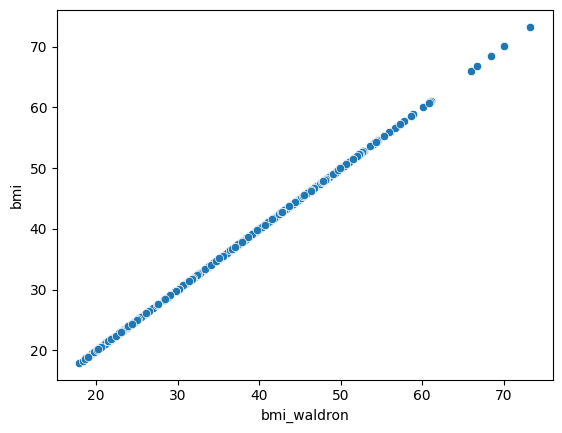

In [67]:
# Check that lab metadata matches
sns.scatterplot(data=abx_chems, x='bmi_waldron', y='bmi') # Amazing!

<Axes: xlabel='hba1c', ylabel='hba1c_waldron'>

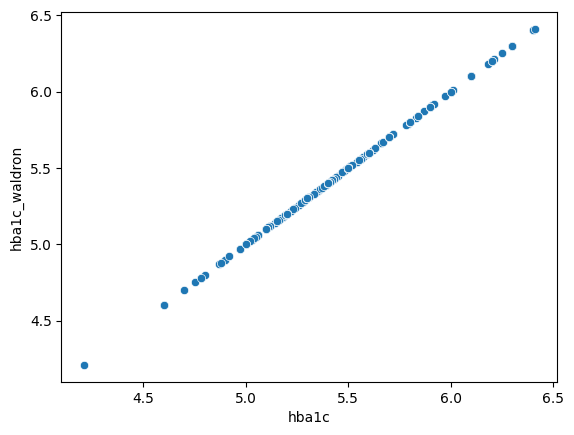

In [106]:
sns.scatterplot(data=abx_chems, x='hba1c', y='hba1c_waldron') # Amazing!

In [68]:
pd.crosstab(abx_chems['country'], abx_chems['center'])

center,Denmark,France,Germany
country,,,
Denmark,143,0,0
France,0,219,0
Germany,0,0,292


In [70]:
pd.crosstab(abx_chems['sex'],abx_chems['gender'])

gender,Female,Male
sex_waldron,,
Female,381,0
Male,0,130


## Merge with Statin use specifically

In [71]:
abx_chems_statin_annot = abx_chems.merge(statin_info[['ID','Statin']].copy(), how='left', on='ID')
pd.crosstab(abx_chems_statin_annot['ANTILIPID_C'], abx_chems_statin_annot['Statin'])

Statin,No,Yes
ANTILIPID_C,,
0,467,0
1,24,186


In [95]:
### Without Waldron

abx_chems_statin_annot_no_waldron = abxuse_load.merge(statin_info[['ID','Statin']].copy(), how='left', on='ID')
pd.crosstab(abx_chems_statin_annot_no_waldron['ANTILIPID_C'], abx_chems_statin_annot_no_waldron['Statin'])

Statin,No,Yes
ANTILIPID_C,,
0,467,0
1,24,186


In [32]:
# Very few people taking non-statin medications it looks like

In [72]:
abx_chems_statin_annot['disease'] = pd.Categorical(abx_chems_statin_annot['disease'], 
                                                   categories=['Healthy', 'Metabolic Syndrome', 
                                                               'Glucose Intolerance', 'Glucose Intolerance;Metabolic Syndrome'],
                                                   ordered=True)

In [73]:
abx_chems_statin_annot.columns

Index(['ID', 'PatientGroup', 'ANTIBIOTICS_TOTAL', 'BETA_LACTAM', 'BISMUTH',
       'FLUOROQUINOLONE', 'FOSFOMYCIN', 'FUSIDIC_ACID', 'GLYCOPEPTIDE',
       'IMIDAZOLE',
       ...
       'Lactobacillus.delbrueckii_CAG03242', 'hba1c_waldron',
       'triglycerides_waldron', 'sex_waldron', 'bmi_waldron', 'control',
       'disease', 'antibiotics_current_use', 'country', 'Statin'],
      dtype='object', length=794)

<Axes: xlabel='Status', ylabel='hba1c'>

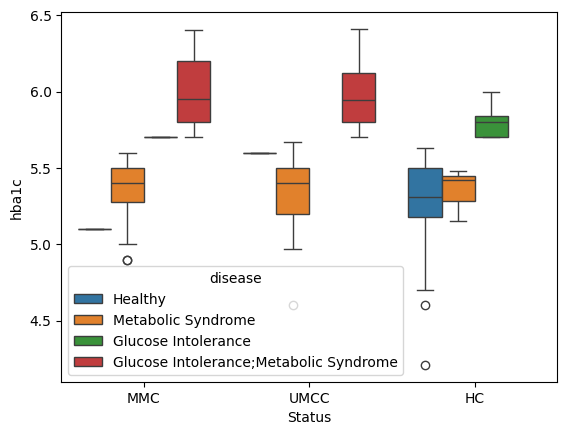

In [99]:
sns.boxplot(data=abx_chems_statin_annot, x='Status', y='hba1c', hue='disease')

<Axes: xlabel='diabetic_status', ylabel='hba1c'>

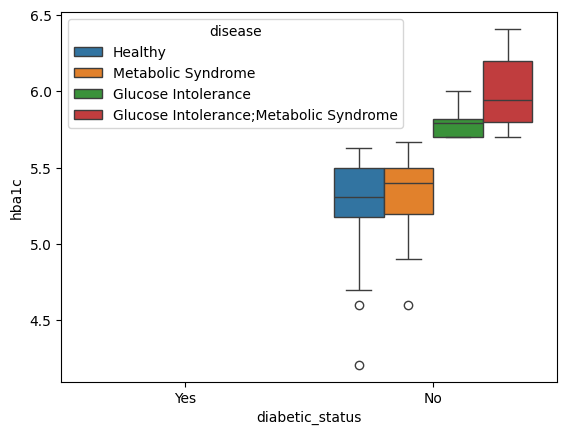

In [75]:
sns.boxplot(data=abx_chems_statin_annot, x='diabetic_status', y='hba1c', hue='disease')

In [ ]:
abx_chems_statin_annot

In [76]:
abx_chems_statin_annot.diabetic_status.value_counts()

diabetic_status
No     461
Yes    216
Name: count, dtype: int64

<Axes: xlabel='diabetic_status', ylabel='hba1c'>

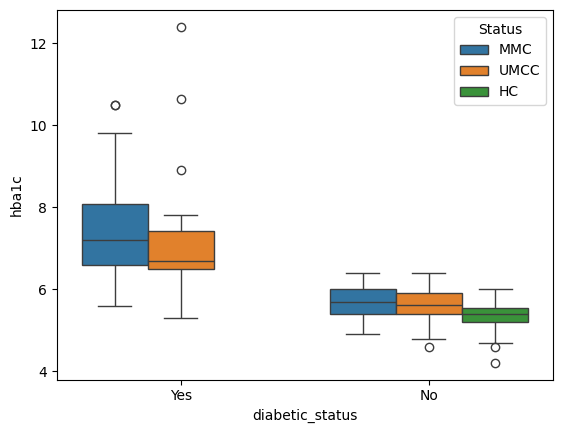

In [77]:
sns.boxplot(data=abx_chems_statin_annot, x='diabetic_status', y='hba1c', hue='Status')

In [78]:
mc_abx_chems_no_t2dm = abx_chems_statin_annot[((abx_chems_statin_annot['disease'] == 'Healthy') |
                                               (abx_chems_statin_annot['disease'] == 'Metabolic Syndrome'))].copy()

mc_abx_chems_no_t2dm['disease'] = pd.Categorical(mc_abx_chems_no_t2dm['disease'], 
                                                 categories=['Healthy', 'Metabolic Syndrome'],
                                                 ordered=True)

In [79]:
mc_abx_chems_no_t2dm.hba1c = mc_abx_chems_no_t2dm.hba1c.astype(float)

In [85]:
abx_chems_statin_annot.disease.notna().sum()

728

In [86]:
abx_chems_statin_annot.diabetic_status.notna().sum()

677

In [87]:
abx_chems_statin_annot.Status.notna().sum()

677

In [89]:
abx_chems_statin_annot.hba1c.notna().sum()

672

In [90]:
abx_chems_statin_annot.antibiotics_current_use.value_counts()

antibiotics_current_use
Yes    370
No     358
Name: count, dtype: int64

In [101]:
pd.crosstab(abx_chems_statin_annot['antibiotics_current_use'], abx_chems_statin_annot['diabetic_status'])

diabetic_status,No
antibiotics_current_use,
No,228
Yes,195


In [ ]:
# Maybe I should avoid merging with the Waldron data?

In [104]:
pd.crosstab(abx_chems_statin_annot_no_waldron['diabetic_status'], abx_chems_statin_annot_no_waldron['Statin'])

Statin,No,Yes
diabetic_status,,
No,371,90
Yes,120,96


In [44]:
forumla_metacardis_interaction_no_t2dm = ('hba1c ~ C(gender) + AGE + BMI + C(disease) + C(CENTER) + '
                                          'C(Statin)*ANTIBIOTICS_TOTAL + microbial_load')

hba1c_model = ols(forumla_metacardis_interaction_no_t2dm, data=mc_abx_chems_no_t2dm).fit()
hba1c_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  hba1c   R-squared:                       0.099
Model:                            OLS   Adj. R-squared:                  0.062
Method:                 Least Squares   F-statistic:                     2.733
Date:                Mon, 22 Jun 2026   Prob (F-statistic):            0.00330
Time:                        18:57:56   Log-Likelihood:                 31.997
No. Observations:                 261   AIC:                            -41.99
Df Residuals:                     250   BIC:                            -2.785
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
======================================================================================================
                                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
Intercept                              4.9635      0.110     45.165      0.000       4.747       5.180
C(Gender)[T.Male]                      0.0253      0.032      0.802      0.423      -0.037       0.087
C(disease)[T.Metabolic Syndrome]      -0.0394      0.047     -0.842      0.401      -0.132       0.053
C(CENTER)[T.France]                   -0.0416      0.042     -0.998      0.319      -0.124       0.041
C(CENTER)[T.Germany]                  -0.0541      0.041     -1.315      0.190      -0.135       0.027
C(Statin)[T.Yes]                      -0.0355      0.050     -0.712      0.477      -0.134       0.063
AGE                                    0.0038      0.001      3.214      0.001       0.001       0.006
BMI                                    0.0069      0.003      2.605      0.010       0.002       0.012
ANTIBIOTICS_TOTAL                      0.0039      0.009      0.439      0.661      -0.014       0.022
C(Statin)[T.Yes]:ANTIBIOTICS_TOTAL     0.0847      0.082      1.039      0.300      -0.076       0.245
microbial_load                      7.041e-14   2.44e-13      0.288      0.773    -4.1e-13    5.51e-13
==============================================================================
Omnibus:                       41.627   Durbin-Watson:                   1.967
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               64.151
Skew:                          -0.936   Prob(JB):                     1.17e-14
Kurtosis:                       4.548   Cond. No.                     1.04e+12
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.04e+12. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

## Merge with metabolite information prior to regression

In [33]:
# Drop a duplicate col before merging with metabolites
metabolites.drop(columns='Status',inplace=True)

In [34]:
metabolites.set_index('ID', inplace=True)

In [35]:
metabs_special_char = metabolites.columns

In [36]:
# Replace special characters
metabolites.columns = metabolites.columns.str.replace('.', '_')
metabolites.columns = metabolites.columns.str.replace('-', '_')
metabolites.columns = metabolites.columns.str.replace(' ', '_')
metabolites.columns = metabolites.columns.str.replace(':', '_')
metabolites.columns = metabolites.columns.str.replace('/', '_')
metabolites.columns = metabolites.columns.str.replace(',', '_')
metabolites.columns = metabolites.columns.str.replace("'", '_')
metabolites.columns = metabolites.columns.str.replace('(', '')
metabolites.columns = metabolites.columns.str.replace(')', '')
metabolites.columns = metabolites.columns.str.replace('*', 'star')
metabolites.columns = metabolites.columns.str.replace(';', '_')
metabolites.columns = metabolites.columns.str.replace('[', '')
metabolites.columns = metabolites.columns.str.replace(']', '')
metabolites.columns = metabolites.columns.str.replace('+', 'plus')

In [37]:
metabs_all_clean = metabolites.columns

In [38]:
# Their data was log-transformed already
# Standardize to match Arivale workflow
metabolites = metabolites.apply(lambda x: (x - x.mean()) / x.std())

In [39]:
metabolites.reset_index(inplace=True)

In [40]:
# Merge metabolites with clients and abx use
clients_abx_metabs = abx_chems_statin_annot.merge(metabolites.drop_duplicates(),
                                                  how='left', on='ID')

In [41]:
clients_abx_metabs.rename(columns=dict(
    zip(metabs_all_clean, "metabolite_" + metabs_all_clean)), inplace=True)

In [42]:
arivale_sig_clean = ['3_4_hydroxyphenyllactate_HPLA', # Added HPLA
                     'glutarate_C5_DC',
                     'citrate',
                     '3_phenylpropionate_hydrocinnamate',
                     '3_hydroxydecanoate',
                     'hippurate',
                     '4_methyl_2_oxopentanoate',
                     'alpha_hydroxyisocaproate',
                     'phenyllactate_PLA',
                     'acetylcarnitine_C2',
                     'indolepropionate',
                     '3_hydroxy_2_ethylpropionate',
                     'alpha_hydroxyisovalerate',
                     '4_hydroxyhippurate',
                     '2_hydroxy_3_methylvalerate',
                     'cinnamoylglycine',
                     'isoursodeoxycholate',
                     'hydantoin_5_propionate',
                     'X_21353', # Removed extra 2 underscores from unknowns
                     'X_12544',
                     'X_12216',
                     'X_15728',
                     'X_24544', 
                     'X_12283',
                     'X_17351']

In [43]:
# Add metabolite_ prefix to make names iterable in regressions
arivale_sig_clean = ["metabolite_" + item for item in arivale_sig_clean]

## Regression
Includes disease (rather than health status) and nationality as a covariate.

In [44]:
clients_abx_metabs.Status.value_counts()

Status
IHD372     702
MMC372     352
HC275      168
UMCC222    157
Name: count, dtype: int64

In [45]:
clients_abx_metabs.disease.value_counts()

disease
Metabolic Syndrome                        287
Glucose Intolerance;Metabolic Syndrome    269
Healthy                                   143
Glucose Intolerance                        29
Name: count, dtype: int64

In [46]:
clients_abx_metabs = clients_abx_metabs[clients_abx_metabs['Status'] != 'IHD372']

In [47]:
clients_abx_metabs.disease.value_counts()

disease
Metabolic Syndrome                        287
Glucose Intolerance;Metabolic Syndrome    269
Healthy                                   143
Glucose Intolerance                        29
Name: count, dtype: int64

In [48]:
pd.crosstab(clients_abx_metabs['disease'], clients_abx_metabs['Statin'])

Statin,No,Yes
disease,,
Glucose Intolerance,25,3
Glucose Intolerance;Metabolic Syndrome,88,40
Healthy,136,5
Metabolic Syndrome,92,34


In [85]:
clients_abx_metabs['disease'] = pd.Categorical(clients_abx_metabs['disease'],
                                               categories=['Healthy', 'Metabolic Syndrome', 
                                                           'Glucose Intolerance', 'Glucose Intolerance;Metabolic Syndrome'],
                                               ordered=True)

In [49]:
len(set(clients_abx_metabs.columns).intersection(set(arivale_sig_clean)))

25

In [64]:
forumla_metacardis_mets = ('{feature} ~ C(gender) + AGE + BMI + microbial_load + C(disease) + C(CENTER) + '
                           'C(ANTIDIAB_C)+ C(Statin)*ANTIBIOTICS_TOTAL')

In [86]:
tests_metacardis_mets = run_tests(arivale_sig_clean, clients_abx_metabs, forumla_metacardis_mets, "ANTIBIOTICS_TOTAL")

Output()

In [87]:
tests_metacardis_mets['feature'] = tests_metacardis_mets['feature'].str.replace('metabolite_', '', regex=False)
tests_metacardis_mets_sig = tests_metacardis_mets[tests_metacardis_mets['q'] < 0.1].sort_values(by='q')

In [88]:
tests_metacardis_mets_sig

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
metabolite_X_12544,X_12544,-0.131051,0.030261,-4.330700,-0.190541,-0.071562,0.000019,416.0,0.000470
metabolite_cinnamoylglycine,cinnamoylglycine,-0.095277,0.029859,-3.190912,-0.153975,-0.036578,0.001529,416.0,0.019116
metabolite_3_phenylpropionate_hydrocinnamate,3_phenylpropionate_hydrocinnamate,-0.084565,0.028593,-2.957540,-0.140775,-0.028355,0.003284,416.0,0.027364
metabolite_isoursodeoxycholate,isoursodeoxycholate,0.084669,0.031042,2.727593,0.023645,0.145694,0.006659,416.0,0.041617
metabolite_hippurate,hippurate,-0.067546,0.028153,-2.399216,-0.122892,-0.012200,0.016884,416.0,0.084418


In [89]:
tests_metacardis_mets_int_total = run_tests(arivale_sig_clean, clients_abx_metabs, forumla_metacardis_mets,
                                            "C(Statin)[T.Yes]:ANTIBIOTICS_TOTAL")
tests_metacardis_mets_int_total.sort_values(by='q')

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
metabolite_hippurate,metabolite_hippurate,0.403499,0.194868,2.070624,0.020414,0.786584,0.039030,416.0,0.273260
metabolite_4_methyl_2_oxopentanoate,metabolite_4_methyl_2_oxopentanoate,0.422976,0.210810,2.006430,0.008551,0.837402,0.045478,416.0,0.273260
metabolite_3_hydroxydecanoate,metabolite_3_hydroxydecanoate,-0.419638,0.227286,-1.846296,-0.866453,0.027177,0.065582,416.0,0.273260
metabolite_cinnamoylglycine,metabolite_cinnamoylglycine,-0.387486,0.206672,-1.874886,-0.793775,0.018803,0.061531,416.0,0.273260
metabolite_4_hydroxyhippurate,metabolite_4_hydroxyhippurate,0.491453,0.218445,2.249783,0.062020,0.920886,0.025002,416.0,0.273260
metabolite_X_17351,metabolite_X_17351,-0.380222,0.201112,-1.890599,-0.775582,0.015138,0.059395,416.0,0.273260
metabolite_alpha_hydroxyisovalerate,metabolite_alpha_hydroxyisovalerate,-0.312776,0.203349,-1.538129,-0.712533,0.086980,0.124802,416.0,0.410880
metabolite_indolepropionate,metabolite_indolepropionate,-0.265368,0.184124,-1.441247,-0.627330,0.096595,0.150291,416.0,0.410880
metabolite_2_hydroxy_3_methylvalerate,metabolite_2_hydroxy_3_methylvalerate,-0.300999,0.224516,-1.340657,-0.742369,0.140370,0.180787,416.0,0.410880
metabolite_alpha_hydroxyisocaproate,metabolite_alpha_hydroxyisocaproate,0.345943,0.251572,1.375121,-0.148616,0.840501,0.169858,416.0,0.410880


In [90]:
clients_abx_metabs['abx_binary'] = clients_abx_metabs['ANTIBIOTICS_TOTAL'].apply(lambda x: 1 if x >= 1 else 0)

In [91]:
# Nothing signficant
forumla_metacardis_mets_binary = ('{feature} ~ C(gender) + AGE + BMI + microbial_load + C(disease) + C(CENTER) + '
                                  'C(ANTIDIAB_C)+ C(Statin)*C(abx_binary)')
tests_metacardis_mets_int_binary = run_tests(arivale_sig_clean, clients_abx_metabs, forumla_metacardis_mets_binary, "C(Statin)[T.Yes]:C(abx_binary)[T.1]")

Output()

In [93]:
# tests_metacardis_mets_int_binary

In [70]:
# tests_metacardis_mets.sort_values(by='q')
# tests_metacardis_mets.to_csv("data/metacardis_regression_tests_total_abx.csv", index=False)

In [71]:
# len(tests_metacardis_mets)

In [53]:
# Using this bc I was curious how we got to the n above
# clients_abx_metabs.dropna(subset=['Status', 'BMI', 'microbial_load', 'CENTER', 'metabolite_isoursodeoxycholate']).Status.value_counts()

Use the small df below to merge onto Arivale data tables

In [72]:
# tests_mc_mets_small = tests_metacardis_mets[['feature','beta', 'q']].copy()
# tests_mc_mets_small.feature = tests_mc_mets_small.feature.str.replace('_HPLA', '')
# tests_mc_mets_small.rename(columns={
#     'beta':'metacardis_beta',
#     'q':'metacardis_q',
#     'feature':'CHEMICAL_NAME'
# }, inplace=True)

In [94]:
# Check the A1c statin_abx interaction
clients_abx_metabs.hba1c = clients_abx_metabs.hba1c.astype(float)

In [95]:
formula_hba1c_interaction = ('hba1c ~ C(gender) + AGE + BMI + C(disease) + C(CENTER) + C(ANTIDIAB_C) +'
                             'C(Statin)*ANTIBIOTICS_TOTAL')

hba1c_model = ols(formula_hba1c_interaction, data=clients_abx_metabs).fit()
hba1c_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  hba1c   R-squared:                       0.678
Model:                            OLS   Adj. R-squared:                  0.669
Method:                 Least Squares   F-statistic:                     78.12
Date:                Thu, 18 Jun 2026   Prob (F-statistic):           3.38e-93
Time:                        15:08:39   Log-Likelihood:                 60.166
No. Observations:                 420   AIC:                            -96.33
Df Residuals:                     408   BIC:                            -47.85
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
========================================================================================================================
                                                           coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------
Intercept                                                5.0116      0.081     61.688      0.000       4.852       5.171
C(Gender)[T.Male]                                       -0.0178      0.023     -0.773      0.440      -0.063       0.028
C(disease)[T.Metabolic Syndrome]                         0.0126      0.038      0.331      0.741      -0.062       0.088
C(disease)[T.Glucose Intolerance]                        0.4524      0.046      9.742      0.000       0.361       0.544
C(disease)[T.Glucose Intolerance;Metabolic Syndrome]     0.6031      0.040     15.057      0.000       0.524       0.682
C(CENTER)[T.France]                                      0.0191      0.029      0.651      0.515      -0.039       0.077
C(CENTER)[T.Germany]                                    -0.0124      0.034     -0.364      0.716      -0.079       0.055
C(ANTIDIAB_C)[T.1]                                    1.051e-15   2.82e-16      3.724      0.000    4.96e-16    1.61e-15
C(Statin)[T.Yes]                                         0.0162      0.036      0.456      0.648      -0.054       0.086
AGE                                                      0.0036      0.001      3.692      0.000       0.002       0.005
BMI                                                      0.0045      0.002      2.542      0.011       0.001       0.008
ANTIBIOTICS_TOTAL                                        0.0041      0.007      0.582      0.561      -0.010       0.018
C(Statin)[T.Yes]:ANTIBIOTICS_TOTAL                      -0.0516      0.050     -1.040      0.299      -0.149       0.046
==============================================================================
Omnibus:                       32.955   Durbin-Watson:                   1.694
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               42.805
Skew:                          -0.616   Prob(JB):                     5.07e-10
Kurtosis:                       3.962   Cond. No.                     3.91e+19
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The smallest eigenvalue is 1.1e-33. This might indicate that there are
strong multicollinearity problems or that the design matrix is singular.
"""

# Merge onto Arivale data

In [55]:
metab_betas = pd.read_csv("data/metabs_betas.csv")
metab_betas.set_index('CHEMICAL_NAME', inplace=True)

metab_qs = pd.read_csv("data/metabs_qs.csv")
metab_qs.set_index('CHEMICAL_NAME', inplace=True)

anns_snapshot = pd.read_csv("data/metabolites_snapshot_updated.csv")
anns = anns_snapshot[['CHEMICAL_NAME','SUB_PATHWAY','SUPER_PATHWAY']].copy()
anns.set_index('CHEMICAL_NAME', inplace=True)

In [56]:
# Are in the same order
# metab_betas.CHEMICAL_NAME == metab_qs.CHEMICAL_NAME

In [57]:
# metab_betas.reset_index(inplace=True)

In [58]:
metab_betas = metab_betas.merge(anns, how='left', on='CHEMICAL_NAME')

I'll have to harmonize the chemical names for merging with the MetaCardis data. Let's create a new var to hold the plot names. 

In [59]:
plot_labs = metab_betas.index.tolist()
metab_betas['plot_name'] = plot_labs
metab_qs['plot_name'] = plot_labs

In [60]:
metab_betas.reset_index(inplace=True)
metab_qs.reset_index(inplace=True)

In [61]:
# Replace special characters
metab_betas.CHEMICAL_NAME = metab_betas.CHEMICAL_NAME.str.replace('-', '_')
metab_betas.CHEMICAL_NAME = metab_betas.CHEMICAL_NAME.str.replace(' ', '_')
metab_betas.CHEMICAL_NAME = metab_betas.CHEMICAL_NAME.str.replace('(', '')
metab_betas.CHEMICAL_NAME = metab_betas.CHEMICAL_NAME.str.replace(')', '')
metab_betas.CHEMICAL_NAME = metab_betas.CHEMICAL_NAME.str.replace('___', '_')

metab_qs.CHEMICAL_NAME = metab_qs.CHEMICAL_NAME.str.replace('-', '_')
metab_qs.CHEMICAL_NAME = metab_qs.CHEMICAL_NAME.str.replace(' ', '_')
metab_qs.CHEMICAL_NAME = metab_qs.CHEMICAL_NAME.str.replace('(', '')
metab_qs.CHEMICAL_NAME = metab_qs.CHEMICAL_NAME.str.replace(')', '')
metab_qs.CHEMICAL_NAME = metab_qs.CHEMICAL_NAME.str.replace('___', '_')

In [62]:
clean_chem_names = metab_betas.CHEMICAL_NAME.tolist()

In [63]:
metab_betas = metab_betas.merge(
    tests_mc_mets_small[['CHEMICAL_NAME','metacardis_beta']].copy(),
    how='left',
    on='CHEMICAL_NAME')

In [64]:
metab_qs = metab_qs.merge(
    tests_mc_mets_small[['CHEMICAL_NAME','metacardis_q']].copy(),
    how='left',
    on='CHEMICAL_NAME')

# Read in data from SOL

In [65]:
sol_results_three = pd.read_excel("data/SOL_metab_res_no_imp.xlsx", sheet_name=0, header=0)
sol_results_six = pd.read_excel("data/SOL_metab_res_no_imp.xlsx", sheet_name=1, header=0)

In [66]:
sol_results_three.chemical_name = sol_results_three.chemical_name.str.replace(
    'N-lactoyl leucine (1-carboxyethyl leucine)','N-lactoyl leucine')

sol_results_six.chemical_name = sol_results_six.chemical_name.str.replace(
    'N-lactoyl leucine (1-carboxyethyl leucine)','N-lactoyl leucine')

In [67]:
sol_results_three.rename(columns={
    'chemical_name':'plot_name', 
    'est':'sol_beta_three',
    'q':'sol_q_three'
}, inplace=True)

sol_results_six.rename(columns={
    'chemical_name':'plot_name', 
    'est':'sol_beta_six',
    'q':'sol_q_six'
}, inplace=True)

In [68]:
metab_betas = metab_betas.merge(
    sol_results_three[['plot_name','sol_beta_three']].copy(),
    how='left',
    on='plot_name')

metab_betas = metab_betas.merge(
    sol_results_six[['plot_name','sol_beta_six']].copy(),
    how='left',
    on='plot_name')

In [69]:
metab_qs = metab_qs.merge(
    sol_results_three[['plot_name','sol_q_three']].copy(),
    how='left',
    on='plot_name')

metab_qs = metab_qs.merge(
    sol_results_six[['plot_name','sol_q_six']].copy(),
    how='left',
    on='plot_name')

## Diener annotations

In [70]:
diener_interactions = pd.read_excel("data/diener_2022_gene_microbe_interactions.xlsx", sheet_name=2, header=0)

In [71]:
diener_interactions_label = diener_interactions[['BIOCHEMICAL_NAME','n_taxa','micro_r2', 'geno_r2', 'total', 'group']].copy()
diener_interactions_label.rename(columns={'BIOCHEMICAL_NAME':'plot_name'}, inplace=True)

In [72]:
diener_interactions_label.plot_name = diener_interactions_label.plot_name.str.replace(
    '1-carboxyethylleucine', 'N-lactoyl leucine')

In [73]:
diener_interactions_label

,plot_name,n_taxa,micro_r2,geno_r2,total,group
0,ethylmalonate,NaN,0.000000e+00,0.509543,5.095434e-01,genetics
1,butyrylcarnitine (C4),1.0,7.698499e-04,0.435463,4.362329e-01,genetics
2,N-acetylcitrulline,NaN,0.000000e+00,0.404305,4.043047e-01,genetics
3,deoxycholic acid glucuronide,7.0,1.638175e-02,0.382920,3.993022e-01,hybrid
4,decadienedioic acid (C10:2-DC)**,1.0,1.569601e-03,0.393814,3.953839e-01,genetics
...,...,...,...,...,...,...
590,"1,5-anhydroglucitol (1,5-AG)",1.0,2.095291e-06,0.000000,2.095291e-06,microbiome
591,myristoylcarnitine (C14),2.0,1.913680e-06,0.000000,1.913680e-06,microbiome
592,lactosyl-N-palmitoyl-sphingosine (d18:1/16:0),1.0,1.207191e-06,0.000000,1.207191e-06,microbiome
593,"sphingomyelin (d18:1/22:2, d18:2/22:1, d16:1/2...",1.0,1.194483e-06,0.000000,1.194483e-06,microbiome


In [74]:
metab_betas = metab_betas.merge(
    diener_interactions_label, 
    on='plot_name',
    how='left')

In [75]:
# metab_betas

In [76]:
metab_betas.fillna({"SUPER_PATHWAY": "Unknown"}, inplace=True)
metab_betas.fillna({"SUB_PATHWAY": "Unknown"}, inplace=True)
metab_betas.fillna({"group": "N/A"}, inplace=True)

In [77]:
metab_betas.group = metab_betas.group.str.replace("hybrid","Hybrid")
metab_betas.group = metab_betas.group.str.replace("microbiome","Microbiome")
metab_betas.group = metab_betas.group.str.replace("genetics","Genetics")

In [78]:
metab_betas.rename(columns={'group':'Determinant_Association'}, inplace=True)

In [79]:
metab_betas.to_csv('data/metabolite_abx_regressions_betas.csv', index=False)
metab_qs.to_csv('data/metabolite_abx_regressions_qs.csv', index=False)

Grab annotated metabolites for Joe to check associations with MEDI-derived dietary information.

In [80]:
df_for_joe = (metab_betas[[
    'CHEMICAL_NAME',
    'plot_name',
    'n_taxa', 
    'micro_r2',
    'geno_r2',
    'total', 
    'Determinant_Association']].copy())

df_for_joe.rename(columns={'CHEMICAL_NAME':'names_clean'}, inplace=True)

In [81]:
joe_df_nums = (df_for_joe).merge(
    anns_snapshot[['feature','CHEMICAL_NAME']].copy(),
    how='left',
    left_on='plot_name',
    right_on='CHEMICAL_NAME'
)

joe_df_nums.drop(columns='plot_name', inplace=True)

In [82]:
joe_df_nums.to_csv('data/abx_sig_mets_with_diener2021_associations.csv')

## Additonal MetaCardis Regression: HC versus UMMC
In their paper, Fromentin et al., look at Cliff's delta. Here I am going to use their metabolite data to look at associations with health status!

In [83]:
# This is how we ran the tests above


In [84]:
clients_abx_metabs.Status.value_counts()

Status
MMC372     176
HC275      168
UMCC222    157
Name: count, dtype: int64

In [85]:
# Look at the metabolites for healthy versus untreated MMC
# clients_control_untreated = clients_abx_metabs[(clients_abx_metabs['Status'] == "HC275") |
# (clients_abx_metabs['Status'] == "UMCC222") | (clients_abx_metabs['Status'] == "UMCC222")]

In [86]:
# clients_control_untreated.loc[:,'Status'] = clients_control_untreated.loc[:,'Status'].apply(
#     lambda x: 0 if x == "HC275" else 1)
# clients_control_untreated.Status.value_counts() 

In [87]:
clients_abx_metabs.CENTER.value_counts()

CENTER
Germany    632
France     624
Denmark    231
Name: count, dtype: int64

In [88]:
forumla_metacardis_status = ('{feature} ~ C(gender) + AGE + BMI + microbial_load + C(Status) + C(CENTER) + '
                             'C(ANTILIPID_C) + C(ANTIDIAB_C) + ANTIBIOTICS_TOTAL')

In [89]:
tests_health_UMMC = run_tests(arivale_sig_clean, clients_abx_metabs, forumla_metacardis_status, "C(Status)[T.UMCC222]")
tests_health_UMMC[tests_health_UMMC.q < 0.1]

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
metabolite_3_phenylpropionate_hydrocinnamate,metabolite_3_phenylpropionate_hydrocinnamate,-0.628802,0.159069,-3.953014,-0.941384,-0.316221,8.915084e-05,478.0,0.001114
metabolite_hippurate,metabolite_hippurate,-0.541794,0.151807,-3.568976,-0.840104,-0.243484,3.955350e-04,478.0,0.002815
metabolite_4_methyl_2_oxopentanoate,metabolite_4_methyl_2_oxopentanoate,0.324797,0.136458,2.380198,0.056648,0.592945,1.770457e-02,478.0,0.073769
metabolite_cinnamoylglycine,metabolite_cinnamoylglycine,-0.820827,0.162594,-5.048336,-1.140334,-0.501320,6.403773e-07,478.0,0.000016
metabolite_isoursodeoxycholate,metabolite_isoursodeoxycholate,0.427448,0.163417,2.615688,0.106323,0.748574,9.193684e-03,478.0,0.045968
metabolite_X_12216,metabolite_X_12216,-0.590399,0.167071,-3.533817,-0.918705,-0.262093,4.504693e-04,478.0,0.002815
metabolite_X_12283,metabolite_X_12283,-0.393394,0.174318,-2.256761,-0.735941,-0.050847,2.448543e-02,478.0,0.087448


In [90]:
tests_health_MMC = run_tests(arivale_sig_clean, clients_abx_metabs, forumla_metacardis_status, "C(Status)[T.MMC372]")
tests_health_MMC[tests_health_MMC.q < 0.1]

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
metabolite_3_phenylpropionate_hydrocinnamate,metabolite_3_phenylpropionate_hydrocinnamate,-0.588462,0.180697,-3.256614,-0.943544,-0.233379,0.001210,478.0,0.010081
metabolite_cinnamoylglycine,metabolite_cinnamoylglycine,-0.756050,0.184701,-4.093367,-1.119000,-0.393099,0.000050,478.0,0.001253
metabolite_X_12216,metabolite_X_12216,-0.659849,0.189788,-3.476776,-1.032794,-0.286903,0.000555,478.0,0.006938


In [91]:
# tests_health_status[tests_health_status.q < 0.1]

In [92]:
tests_health_UMMC.to_csv("data/metacardis_regression_tests_healthy_UMMC.csv", index=False)
tests_health_MMC.to_csv("data/metacardis_regression_tests_healthy_MMC.csv", index=False)

## Check overlap between omics and hba1c

In [93]:
mc_data_waldron = pd.read_csv('data/MetaCardis_2020_a_sample.tsv', sep='\t')
mc_labs = mc_data_waldron[['study_name', 'subject_id', 'sample_id', 'sex',
                        'age_max', 'age_min', 'bmi','control', 'disease', 
                        'antibiotics_current_use', 'country',
                        'biomarker_name', 'biomarker_unit', 'biomarker_value',
                       ]].copy()
mc_labs['subject_id'] = mc_labs['subject_id'].str[2:]
mc_labs = mc_labs.dropna(subset='biomarker_name')
mc_labs['biomarker_name'] = mc_labs['biomarker_name'].str.split(";")
mc_labs['biomarker_unit'] = mc_labs['biomarker_unit'].str.split(";")
mc_labs['biomarker_value'] = mc_labs['biomarker_value'].str.split(";")
mc_labs_exploded = mc_labs.explode(['biomarker_name', 'biomarker_unit', 'biomarker_value'])
mc_labs_exploded.biomarker_value = mc_labs_exploded.biomarker_value.astype(float)
mc_labs_exploded = mc_labs_exploded.set_index("subject_id")

mc_labs_pivoted = mc_labs_exploded.pivot(
    columns='biomarker_name', 
    values=['biomarker_unit', 'biomarker_value']
)

mc_labs_pivoted.columns = [f"{biomarker}_{metric}" for metric, biomarker in mc_labs_pivoted.columns]
mc_labs_pivoted.columns = mc_labs_pivoted.columns.str.lower()
mc_labs_pivoted.columns = mc_labs_pivoted.columns.str.replace("_biomarker", "")
mc_labs_pivoted.reset_index(inplace=True)
mc_chems_completed = mc_labs_pivoted.merge(mc_labs, how='right', on='subject_id')

In [94]:
mc_data_waldron.columns

Index(['study_name', 'subject_id', 'sample_id', 'target_condition',
       'target_condition_ontology_term_id', 'control',
       'control_ontology_term_id', 'country', 'country_ontology_term_id',
       'body_site', 'body_site_ontology_term_id', 'age_group',
       'age_group_ontology_term_id', 'age_max', 'age_min',
       'antibiotics_current_use', 'biomarker_name', 'biomarker_unit',
       'biomarker_value', 'bmi', 'curator', 'disease',
       'disease_ontology_term_id', 'feces_phenotype', 'feces_phenotype_value',
       'feces_phenotype_ontology_term_id', 'location', 'ncbi_accession',
       'pmid', 'sequencing_platform', 'sex', 'sex_ontology_term_id', 'smoker',
       'smoker_ontology_term_id', 'treatment', 'treatment_ontology_term_id',
       'westernized'],
      dtype='object')

In [95]:
# mc_data_waldron['pmid']

In [96]:
test = mc_data_waldron[['study_name', 'subject_id', 'sample_id', 'sex',
                        'age_max', 'age_min', 'bmi','control', 'disease', 
                        'antibiotics_current_use', 'country',
                        'biomarker_name', 'biomarker_unit', 'biomarker_value',
                       ]].copy()

In [97]:
test['subject_id'] = test['subject_id'].str[2:]

In [98]:
test.biomarker_name.value_counts()

biomarker_name
Glycosylated_Hemoglobin;High_Sensitivity_C-Reactive_Protein;LDL_Particles;Triglyceride    821
Glycosylated_Hemoglobin;LDL_Particles;Triglyceride                                         15
High_Sensitivity_C-Reactive_Protein;LDL_Particles;Triglyceride                              5
Glycosylated_Hemoglobin;High_Sensitivity_C-Reactive_Protein;Triglyceride                    3
Name: count, dtype: int64

In [99]:
# labs_metacardis = ['Glycosylated_Hemoglobin',
#                    'High_Sensitivity_C-Reactive_Protein', 
#                    'LDL_Particles',
#                    'Triglyceride']

In [100]:
test = test.dropna(subset='biomarker_name')

In [101]:
test['biomarker_name'] = test['biomarker_name'].str.split(";")
test['biomarker_unit'] = test['biomarker_unit'].str.split(";")
test['biomarker_value'] = test['biomarker_value'].str.split(";")

In [102]:
df_exploded = test.explode(['biomarker_name', 'biomarker_unit', 'biomarker_value'])

In [103]:
df_exploded.biomarker_value = df_exploded.biomarker_value.astype(float)

In [104]:
df_exploded = df_exploded.set_index("subject_id")

In [105]:
# 2. Reshape the data from long format to wide format
df_pivoted = df_exploded.pivot(
    columns='biomarker_name', 
    values=['biomarker_unit', 'biomarker_value']
)

In [106]:
# 3. Flatten the multi-level column headers (e.g., ('biomarker_value', 'biomarker_A'))
df_pivoted.columns = [f"{biomarker}_{metric}" for metric, biomarker in df_pivoted.columns]

<Axes: >

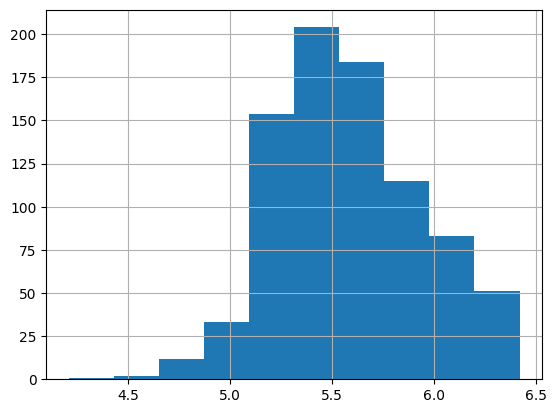

In [107]:
df_pivoted.Glycosylated_Hemoglobin_biomarker_value.hist()

In [108]:
df_pivoted.columns = df_pivoted.columns.str.lower()
df_pivoted.columns = df_pivoted.columns.str.replace("_biomarker", "")
df_pivoted.reset_index(inplace=True)
mc_chems = df_pivoted.merge(test, how='right', on='subject_id')

In [111]:
# clients_abx_metabs

In [112]:
mc_chems = df_pivoted.merge(test, how='right', on='subject_id')

In [113]:
mc_chems

,subject_id,glycosylated_hemoglobin_unit,high_sensitivity_c-reactive_protein_unit,ldl_particles_unit,triglyceride_unit,glycosylated_hemoglobin_value,high_sensitivity_c-reactive_protein_value,ldl_particles_value,triglyceride_value,study_name,...,age_max,age_min,bmi,control,disease,antibiotics_current_use,country,biomarker_name,biomarker_unit,biomarker_value
0,x10MCx1134,mmol/mol,mg/L,mg/dL,mg/dL,6.0,1.3,140.673726,97.940706,MetaCardis_2020_a,...,65,18,44.365888,Case,Glucose Intolerance;Metabolic Syndrome,No,France,"[Glycosylated_Hemoglobin, High_Sensitivity_C-R...","[mmol/mol, mg/L, mg/dL, mg/dL]","[6, 1.3, 140.673726, 97.940706]"
1,x10MCx1146,mmol/mol,mg/L,mg/dL,mg/dL,6.3,453.0,125.708436,124.192854,MetaCardis_2020_a,...,130,65,33.549292,Case,Glucose Intolerance;Metabolic Syndrome,No,France,"[Glycosylated_Hemoglobin, High_Sensitivity_C-R...","[mmol/mol, mg/L, mg/dL, mg/dL]","[6.3, 453, 125.708436, 124.192854]"
2,x10MCx1150,mmol/mol,NaN,mg/dL,mg/dL,5.9,NaN,115.731576,60.58188,MetaCardis_2020_a,...,65,18,39.851858,Case,Glucose Intolerance;Metabolic Syndrome,NaN,France,"[Glycosylated_Hemoglobin, LDL_Particles, Trigl...","[mmol/mol, mg/dL, mg/dL]","[5.9, 115.731576, 60.58188]"
3,x10MCx1162,mmol/mol,mg/L,mg/dL,mg/dL,5.4,1.95,147.657528,96.931008,MetaCardis_2020_a,...,65,18,36.617894,Study Control,Metabolic Syndrome,No,France,"[Glycosylated_Hemoglobin, High_Sensitivity_C-R...","[mmol/mol, mg/L, mg/dL, mg/dL]","[5.4, 1.95, 147.657528, 96.931008]"
4,x10MCx1171,mmol/mol,mg/L,mg/dL,mg/dL,5.7,2.94,121.717692,137.318928,MetaCardis_2020_a,...,65,18,39.013180,Case,Glucose Intolerance;Metabolic Syndrome,Yes,France,"[Glycosylated_Hemoglobin, High_Sensitivity_C-R...","[mmol/mol, mg/L, mg/dL, mg/dL]","[5.7, 2.94, 121.717692, 137.318928]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
839,x30MCx3375,mmol/mol,mg/L,mg/dL,mg/dL,5.3,0.68,127.611,52.2563,MetaCardis_2020_a,...,65,18,NaN,Study Control,Healthy,No,Denmark,"[Glycosylated_Hemoglobin, High_Sensitivity_C-R...","[mmol/mol, mg/L, mg/dL, mg/dL]","[5.3, 0.68, 127.611, 52.2563]"
840,x30MCx3376,mmol/mol,mg/L,mg/dL,mg/dL,5.3,2.79,139.212,125.7694,MetaCardis_2020_a,...,65,18,NaN,Study Control,Metabolic Syndrome,Yes,Denmark,"[Glycosylated_Hemoglobin, High_Sensitivity_C-R...","[mmol/mol, mg/L, mg/dL, mg/dL]","[5.3, 2.79, 139.212, 125.7694]"
841,x30MCx3379,mmol/mol,mg/L,mg/dL,mg/dL,5.4,797.0,100.542,94.7699,MetaCardis_2020_a,...,65,18,NaN,Study Control,Metabolic Syndrome,Yes,Denmark,"[Glycosylated_Hemoglobin, High_Sensitivity_C-R...","[mmol/mol, mg/L, mg/dL, mg/dL]","[5.4, 797, 100.542, 94.7699]"
842,x30MCx3384,mmol/mol,mg/L,mg/dL,mg/dL,5.4,2.82,139.212,74.3988,MetaCardis_2020_a,...,65,18,NaN,Study Control,Metabolic Syndrome,Yes,Denmark,"[Glycosylated_Hemoglobin, High_Sensitivity_C-R...","[mmol/mol, mg/L, mg/dL, mg/dL]","[5.4, 2.82, 139.212, 74.3988]"


In [114]:
mc_chems_small = mc_chems[['subject_id', 'sex', 'bmi', 
                           'country', 'control', 'disease',
                           'antibiotics_current_use',
                           'glycosylated_hemoglobin_value', 
                           'high_sensitivity_c-reactive_protein_value',
                           'ldl_particles_value',
                           'triglyceride_value'
                          ]].copy()

In [115]:
mc_chems_small.rename(columns={'subject_id':'ID'}, inplace=True)

In [116]:
mc_abx_chems = clients_abx_metabs.merge(mc_chems_small, how='left', on='ID')

In [117]:
mc_abx_chems.glycosylated_hemoglobin_value.describe()

count     651.0
unique    128.0
top         5.5
freq       46.0
Name: glycosylated_hemoglobin_value, dtype: float64

In [118]:
mc_abx_chems.glycosylated_hemoglobin_value = mc_abx_chems.glycosylated_hemoglobin_value.astype(float)

In [119]:
## Let's see if the data agree with one another re: disease status, bmi, etc

In [120]:
# mc_abx_chems.columns.tolist()

<Axes: xlabel='BMI', ylabel='bmi'>

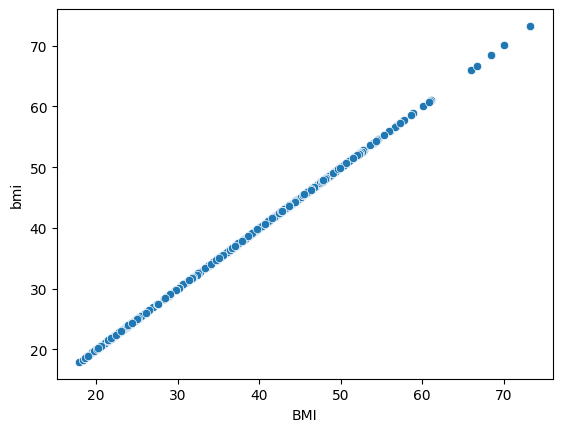

In [121]:
sns.scatterplot(data=mc_abx_chems, x='BMI', y='bmi') # Amazing!

CENTER,Denmark,France,Germany
country,,,
Denmark,143,0,0
France,0,219,0
Germany,0,0,292


Gender,Female,Male
sex,,
Female,381,0
Male,0,130


In [124]:
pd.crosstab(mc_abx_chems['Status'],mc_abx_chems['disease'])

disease,Glucose Intolerance,Glucose Intolerance;Metabolic Syndrome,Healthy,Metabolic Syndrome
Status,,,,
HC275,26,0,138,3
MMC372,1,40,1,32
UMCC222,0,48,1,59


In [125]:
pd.crosstab(mc_abx_chems['Status'],mc_abx_chems['control'])

control,Case,Study Control
Status,,
HC275,4,163
MMC372,41,33
UMCC222,48,60


<Axes: xlabel='Status', ylabel='glycosylated_hemoglobin_value'>

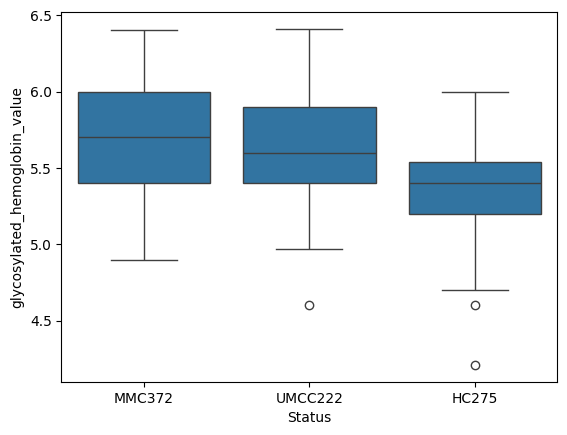

In [126]:
# Maybe disease is the most reliable? Let's look at their A1cs
sns.boxplot(data=mc_abx_chems, x='Status', y='glycosylated_hemoglobin_value')

<Axes: xlabel='disease', ylabel='glycosylated_hemoglobin_value'>

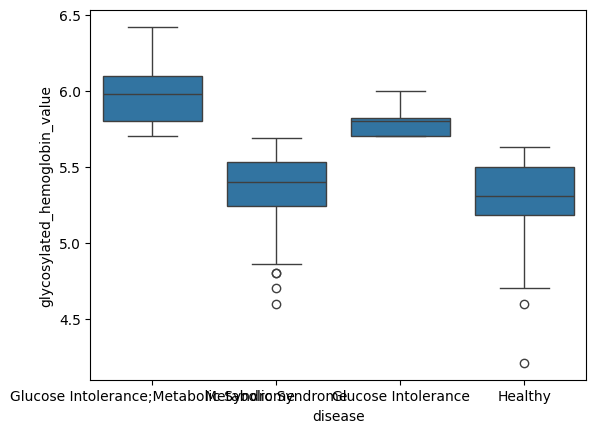

In [127]:
sns.boxplot(data=mc_abx_chems, x='disease', y='glycosylated_hemoglobin_value')

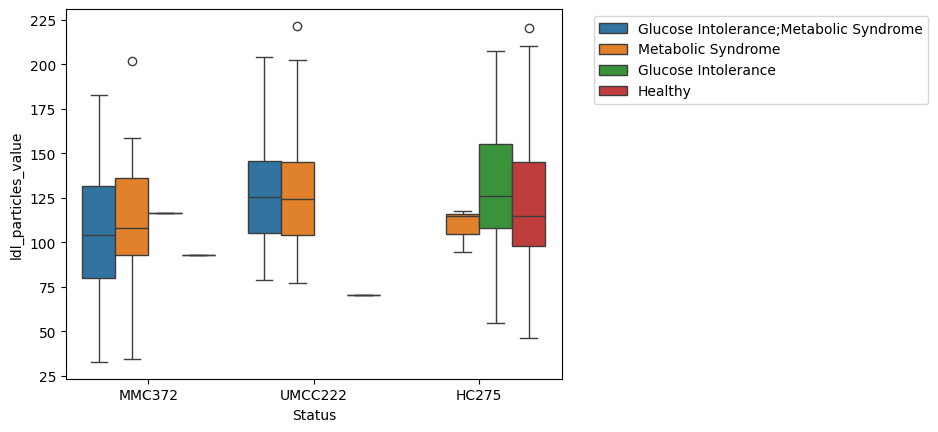

In [128]:
sns.boxplot(data=mc_abx_chems, x='Status', y='ldl_particles_value', hue='disease')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

In [129]:
# re do my regressions!

In [130]:
forumla_metacardis_mets_new = ('{feature} ~ C(gender) + AGE + BMI + microbial_load + C(disease) + C(CENTER) + '
                           'C(ANTILIPID_C) + C(ANTIDIAB_C) + ANTIBIOTICS_TOTAL')
tests_metacardis_mets_new = run_tests(arivale_sig_clean, mc_abx_chems, forumla_metacardis_mets_new, "ANTIBIOTICS_TOTAL")
tests_metacardis_mets_new['feature'] = tests_metacardis_mets_new['feature'].str.replace('metabolite_', '', regex=False)
tests_metacardis_mets_new_sig = tests_metacardis_mets_new[tests_metacardis_mets_new['q'] < 0.1].sort_values(by='q')

Output()

In [131]:
tests_metacardis_mets_new_sig

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
metabolite_X_12544,X_12544,-0.131211,0.031108,-4.217951,-0.192405,-0.070017,0.000032,343.0,0.000797
metabolite_3_phenylpropionate_hydrocinnamate,3_phenylpropionate_hydrocinnamate,-0.082311,0.029088,-2.829733,-0.139532,-0.025091,0.004943,343.0,0.041192
metabolite_cinnamoylglycine,cinnamoylglycine,-0.089723,0.030633,-2.928966,-0.149982,-0.029463,0.003637,343.0,0.041192
metabolite_isoursodeoxycholate,isoursodeoxycholate,0.080105,0.031439,2.547914,0.018259,0.141951,0.011288,343.0,0.070553


In [132]:
pd.crosstab(mc_abx_chems['ANTILIPID_C'],mc_abx_chems['disease'])

disease,Glucose Intolerance,Glucose Intolerance;Metabolic Syndrome,Healthy,Metabolic Syndrome
ANTILIPID_C,,,,
0,25,167,138,225
1,3,62,4,30


In [133]:
mc_abx_chems['abx_binary'] = mc_abx_chems['ANTIBIOTICS_TOTAL'].apply(lambda x: 1 if x >= 1 else 0)

In [134]:
## Add statin use specifically

In [137]:
statin_annot = mc_abx_chems.merge(other_drugs[['ID','Statin']].copy(), how='left', on='ID')

In [138]:
pd.crosstab(statin_annot['abx_binary'], statin_annot['Statin'])

Statin,No,Yes
abx_binary,,
0,269,120
1,222,66


In [139]:
# mc_abx_chems['ANTILIPID_C'].value_counts()

In [146]:
statin_annot['disease'] = pd.Categorical(statin_annot['disease'], 
                                         categories=['Healthy', 'Metabolic Syndrome', 
                                                     'Glucose Intolerance', 'Glucose Intolerance;Metabolic Syndrome'],
                                         ordered=True)

In [148]:
mc_abx_chems_no_t2dm = statin_annot[((statin_annot['disease'] == 'Healthy') | (statin_annot['disease'] == 'Metabolic Syndrome'))].copy()
# healthy = mc_abx_chems[(mc_abx_chems['disease'] == 'Healthy')].copy()

mc_abx_chems_no_t2dm['disease'] = pd.Categorical(mc_abx_chems_no_t2dm['disease'], 
                                         categories=['Healthy', 'Metabolic Syndrome'],
                                         ordered=True)

forumla_metacardis_interaction_no_t2dm = ('glycosylated_hemoglobin_value ~ C(gender) + AGE + BMI + C(disease) + C(CENTER) + '
                                       'C(Statin)*C(abx_binary)')

hba1c_model = ols(forumla_metacardis_interaction_no_t2dm, data=statin_annot).fit()
hba1c_model.summary()

In [149]:
mc_abx_chems_no_t2dm['disease'] = pd.Categorical(mc_abx_chems_no_t2dm['disease'], 
                                         categories=['Healthy', 'Metabolic Syndrome'],
                                         ordered=True)

In [154]:
forumla_metacardis_interaction_no_t2dm = ('glycosylated_hemoglobin_value ~ C(gender) + AGE + BMI + C(disease) + C(CENTER) + '
                                       'C(Statin)*C(abx_binary)')

hba1c_model = ols(forumla_metacardis_interaction_no_t2dm, data=statin_annot).fit()
hba1c_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                  OLS Regression Results                                 
=========================================================================================
Dep. Variable:     glycosylated_hemoglobin_value   R-squared:                       0.678
Model:                                       OLS   Adj. R-squared:                  0.669
Method:                            Least Squares   F-statistic:                     78.10
Date:                           Thu, 18 Jun 2026   Prob (F-statistic):           3.53e-93
Time:                                   14:17:46   Log-Likelihood:                 60.120
No. Observations:                            420   AIC:                            -96.24
Df Residuals:                                408   BIC:                            -47.76
Df Model:                                     11                                         
Covariance Type:                       nonrobust                                         
========================================================================================================================
                                                           coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------
Intercept                                                5.0221      0.082     61.266      0.000       4.861       5.183
C(Gender)[T.Male]                                       -0.0192      0.023     -0.832      0.406      -0.065       0.026
C(disease)[T.Metabolic Syndrome]                         0.0142      0.038      0.371      0.711      -0.061       0.089
C(disease)[T.Glucose Intolerance]                        0.4533      0.046      9.758      0.000       0.362       0.545
C(disease)[T.Glucose Intolerance;Metabolic Syndrome]     0.6056      0.040     15.035      0.000       0.526       0.685
C(CENTER)[T.France]                                      0.0205      0.029      0.699      0.485      -0.037       0.078
C(CENTER)[T.Germany]                                    -0.0058      0.034     -0.171      0.864      -0.073       0.061
C(Statin)[T.Yes]                                         0.0090      0.037      0.244      0.807      -0.063       0.081
C(abx_binary)[T.1]                                      -0.0119      0.024     -0.501      0.616      -0.059       0.035
C(Statin)[T.Yes]:C(abx_binary)[T.1]                     -0.0357      0.054     -0.655      0.513      -0.143       0.071
AGE                                                      0.0035      0.001      3.642      0.000       0.002       0.005
BMI                                                      0.0045      0.002      2.530      0.012       0.001       0.008
==============================================================================
Omnibus:                       35.509   Durbin-Watson:                   1.691
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               48.012
Skew:                          -0.634   Prob(JB):                     3.75e-11
Kurtosis:                       4.065   Cond. No.                         515.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [153]:
pd.crosstab(mc_abx_chems_no_t2dm['abx_binary'], mc_abx_chems_no_t2dm['Statin'])

Statin,No,Yes
abx_binary,,
0,120,29
1,108,10


<Axes: xlabel='Statin', ylabel='glycosylated_hemoglobin_value'>

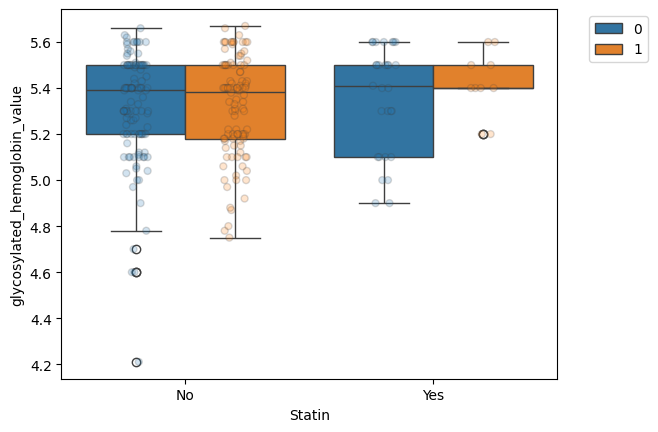

In [152]:
sns.boxplot(data=mc_abx_chems_no_t2dm, x='Statin', y='glycosylated_hemoglobin_value', hue='abx_binary')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
sns.stripplot(data=mc_abx_chems_no_t2dm, x='Statin', y ='glycosylated_hemoglobin_value',
              hue='abx_binary',alpha=0.2, jitter=True, dodge=True, legend=False,
              marker="o",          # Standard circle marker
              facecolors="none",   # Removes the fill (makes it open)
              linewidth=1)

In [131]:
mc_abx_chems.ldl_particles_value = mc_abx_chems.ldl_particles_value.astype(float)

<Axes: xlabel='ANTIBIOTICS_TOTAL', ylabel='metabolite_cinnamoylglycine'>

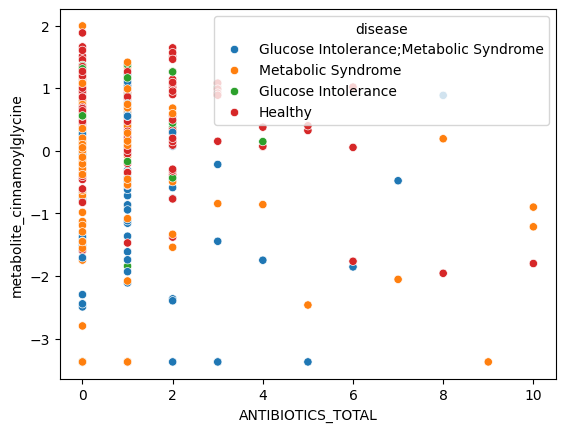

In [104]:
sns.scatterplot(data=mc_abx_chems, x='ANTIBIOTICS_TOTAL', y='metabolite_cinnamoylglycine', hue='ANTILIPID_C')

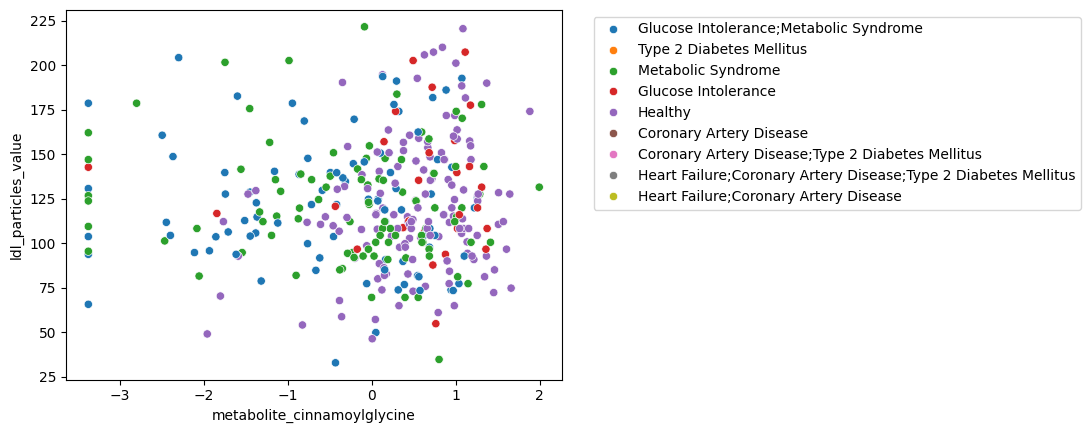

In [182]:
sns.scatterplot(data=mc_abx_chems, x='metabolite_cinnamoylglycine', y='ldl_particles_value', hue='disease')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

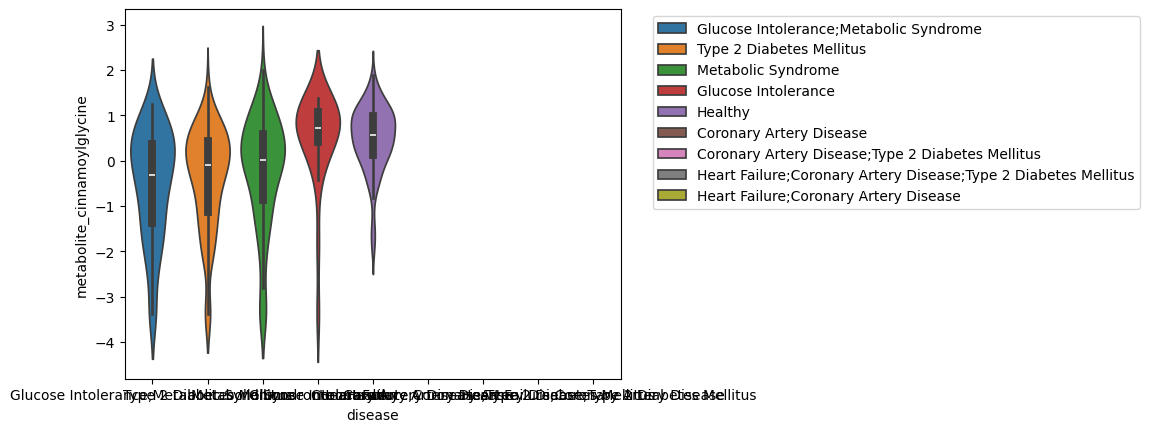

In [183]:
sns.violinplot(data=mc_abx_chems, x='disease', y='metabolite_cinnamoylglycine', hue='disease')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

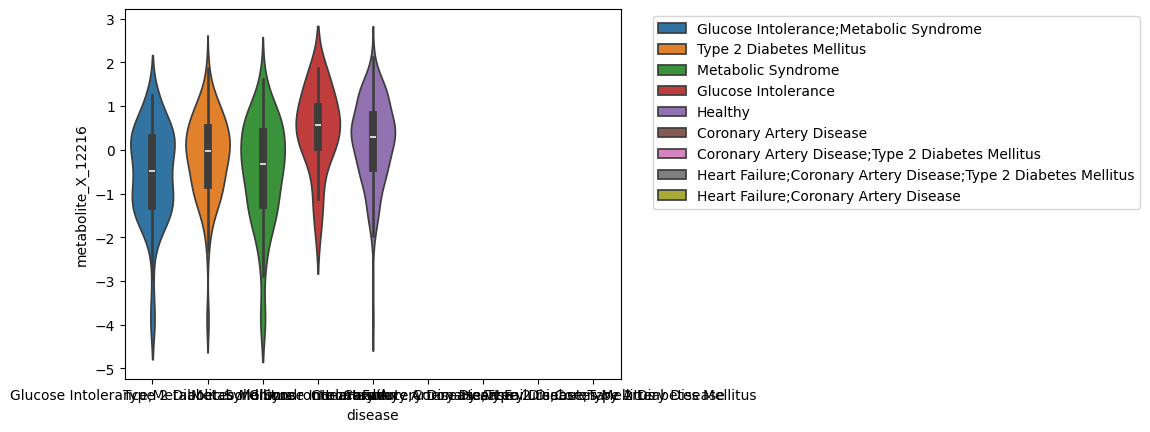

In [170]:
sns.violinplot(data=mc_abx_chems, x='disease', y='metabolite_X_12216', hue='disease')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')